In [3]:
import pandas as pd
import torch
import torch.nn as nn
# import torch.functional as F
import torch.nn.functional as F
import torch_geometric as tg
# import torch_geometric.nn as tg_nn
from torch_geometric.data import Data
from torch_geometric.transforms import RandomNodeSplit
from sklearn.metrics import confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay,classification_report
import matplotlib.pyplot as plt
# Darpa Time stamps: every 5 minutes

In [226]:
# torch.nn.Enc

In [4]:
test = pd.read_csv("/Users/tony/Downloads/Graph-Sketch/data/DARPA/darpa_edges.txt")

# test_labels = ["Src","Dest","Time-Step"]
test.columns = ["Src","Dest","Time-Step"]
test_edge_idx = test.drop(labels=["Time-Step"],axis=1)
test_edge_attribute = test["Time-Step"]
test_y = pd.read_csv("/Users/tony/Downloads/Graph-Sketch/data/DARPA/darpa_ground_truth.csv")

test

,Src,Dest,Time-Step
0,7577,9765,1
1,9764,9763,2
2,9764,9763,2
3,9765,7577,3
4,9765,7577,3
...,...,...,...
4554338,10215,9763,46571
4554339,10215,9763,46571
4554340,10215,9763,46571
4554341,10215,9763,46571


In [12]:
test
# dict(zip(test["Time-Step"],test["Src"]))
test.set_index("Time-Step")[["Src"],["Dest"]].to_dict()

InvalidIndexError: (['Src'], ['Dest'])

In [3]:
test_edge_attribute

0              1
1              2
2              2
3              3
4              3
           ...  
4554338    46571
4554339    46571
4554340    46571
4554341    46571
4554342    46572
Name: Time-Step, Length: 4554343, dtype: int64

In [229]:
test_y

,0
0,0
1,0
2,0
3,0
4,0
...,...
4554338,0
4554339,0
4554340,0
4554341,0


In [230]:
num_nodes = int(max(test_edge_idx['Src'].max(), test_edge_idx['Dest'].max())) + 1

# 2. Create a dummy node feature tensor (e.g., 16-dimensional components)
node_features_dim = 2
tensor_x = torch.ones((num_nodes, node_features_dim), dtype=torch.float)

In [231]:
# tensor_edge = torch.tensor(test_edge_idx.values, dtype=torch.long).t().contiguous() # Shape: [2, num_edges]
# tensor_y = torch.tensor(test_y.values, dtype=torch.float)
# tensor_edge_attribute = torch.tensor(test_edge_attribute.values, dtype=torch.float).view(-1, 1) # Shape: [num_edges, 1]
# tensor_edge = torch.Tensor(test_edge_idx.values)
# tensor_y = torch.tensor(test_y.values, dtype=torch.float).view(-1, 1)
# tensor_edge_attribute = torch.Tensor(test_edge_attribute.values)
num_nodes = int(max(test_edge_idx['Src'].max(), test_edge_idx['Dest'].max())) + 1

# Define your desired feature dimension here (e.g., 8)
node_features_dim = 8 
tensor_x = torch.ones((num_nodes, node_features_dim), dtype=torch.float)

tensor_edge = torch.tensor(test_edge_idx.values, dtype=torch.long).t().contiguous()
tensor_edge_attribute = torch.tensor(test_edge_attribute.values, dtype=torch.float).view(-1, 1)
tensor_y = torch.tensor(test_y.values, dtype=torch.float).view(-1, 1)

In [232]:
num_nodes = int(max(test_edge_idx['Src'].max(), test_edge_idx['Dest'].max())) + 1

node_features_dim = 8 
tensor_x = torch.ones((num_nodes, node_features_dim), dtype=torch.float)

tensor_edge = torch.tensor(test_edge_idx.values, dtype=torch.long).t().contiguous()

# FIX: Normalize time-steps so the values don't explode the network gradients
raw_timestamps = torch.tensor(test_edge_attribute.values, dtype=torch.float)
normalized_timestamps = (raw_timestamps - raw_timestamps.mean()) / (raw_timestamps.std() + 1e-8)
tensor_edge_attribute = normalized_timestamps.view(-1, 1)

tensor_y = torch.tensor(test_y.values, dtype=torch.float).view(-1, 1)

In [233]:
data_load = Data(x=tensor_x,edge_index=tensor_edge,y=tensor_y,edge_attr=tensor_edge_attribute)

import numpy as np

# Get the total number of edges
num_edges = data_load.y.size(0)

# Create indices and shuffle
indices = np.arange(num_edges)
np.random.shuffle(indices)

# Define your split sizes
train_size = int(0.8 * num_edges)
val_size = int(0.1 * num_edges)

# Initialize masks with the exact same size
train_mask = torch.zeros(num_edges, dtype=torch.bool)
val_mask = torch.zeros(num_edges, dtype=torch.bool)
test_mask = torch.zeros(num_edges, dtype=torch.bool)

# Assign indices using precise boundaries
train_mask[indices[:train_size]] = True
val_mask[indices[train_size:train_size + val_size]] = True
test_mask[indices[train_size + val_size:]] = True

# Update the data object
data_load.train_mask = train_mask
data_load.val_mask = val_mask
data_load.test_mask = test_mask

# train_test_split_ratio = RandomNodeSplit(num_splits=2,num_val=0.15,num_test=0.25)
# data_load = train_test_split_ratio(data_load)
# data_load.

In [234]:
data_load

Data(x=[25525, 8], edge_index=[2, 4554343], edge_attr=[4554343, 1], y=[4554343, 1], train_mask=[4554343], val_mask=[4554343], test_mask=[4554343])

In [235]:
# train_indices = data_load.train_mask.nonzero(as_tuple=True)[0].cpu().numpy()
# train_labels = tensor_y[train_indices].cpu().numpy()

# pos_train_idx = train_indices[train_labels == 1]
# neg_train_idx = train_indices[train_labels == 0]

# # Subsample the majority class to match the minority class count
# np.random.shuffle(neg_train_idx)
# balanced_neg_idx = neg_train_idx[:len(pos_train_idx)]

# # Construct a brand new balanced training mask
# balanced_train_idx = np.concatenate([pos_train_idx, balanced_neg_idx])
# balanced_train_mask = torch.zeros_like(data_load.train_mask, dtype=torch.bool)
# balanced_train_mask[balanced_train_idx] = True

# # Assign it back to your dataset object
# data_load.train_mask = balanced_train_mask

In [236]:
class BaseModel(nn.Module):
    def __init__(self, input_size):
        super(BaseModel, self).__init__()
        # Explicitly set edge_dim=1 so GENConv knows the edge attribute size
        self.gat = tg.nn.GATv2Conv(input_size, input_size * 2, edge_dim=1)
        self.gen1 = tg.nn.GENConv(input_size*2, input_size * 4, edge_dim=1)

        # Note: GATv2Conv also accepts edge_dim if you want to pass edge_attr there too, 
        # but in your current forward function, you are passing 3 arguments to ga1.
        # Let's fix ga1 as well to prevent the next potential error:
        # self.ga1 = tg.nn.GATv2Conv(input_size * 2, input_size * 4)
        
        self.ln1 = nn.Linear(input_size * 4, 16)
        self.ln2 = nn.Linear(16, 1)

    def forward(self, data):
        x, edge_index, edge_attr = data.x, data.edge_index, data.edge_attr
        
        # 1. First layer uses edge_attr (now dimensions will match via edge_dim=1)
        x = self.gat(x, edge_index, edge_attr=edge_attr)
        x = F.leaky_relu(x)
        x = self.gen1(x, edge_index, edge_attr=edge_attr) 

        # 2. Second layer (GATv2Conv) - do not pass edge_attr unless you add edge_dim there too
        # x = self.ga1(x, edge_index) 
        
        # 3. Final link prediction / classification aggregation
        row, col = edge_index
        edge_repr = x[row] + x[col]
        
        edge_repr = self.ln1(edge_repr)
        edge_repr = F.relu(edge_repr)
        out = self.ln2(edge_repr)
        # return torch.sigmoid(out)
        return out



In [237]:
class AdvancedModel(nn.Module):
    def __init__(self,input_size):
        super(AdvancedModel,self).__init__()
        self.gat1 = tg.nn.GATv2Conv(input_size,input_size*2,edge_dim=1)
        self.gen1 = tg.nn.GENConv(input_size*2,input_size*4,edge_dim=1)
        self.gen2 = tg.nn.GENConv(input_size*4,input_size*8,edge_dim=1)
        self.ln1 = nn.Linear(input_size*8,32)
        self.ln2 = nn.Linear(32,1)

    def forward(self,data):
        x,edge_index,edge_attr = data.x,data.edge_index,data.edge_attr
        x = self.gat1(x,edge_index,edge_attr)
        x = nn.functional.leaky_relu_(x)
        x = self.gen1(x,edge_index,edge_attr)
        x = nn.functional.leaky_relu_(x)
        x = self.gen2(x,edge_index,edge_attr)
        row, col = edge_index
        edge_repr = x[row] + x[col]
        
        edge_repr = self.ln1(edge_repr)
        edge_repr = F.relu(edge_repr)
        out = self.ln2(edge_repr)
        # return torch.sigmoid(out)
        return out


In [238]:
class GATModel(nn.Module):
    def __init__(self,input_size):
        super(GATModel,self).__init__()
        self.gat1 = tg.nn.GATv2Conv(input_size,input_size*2,edge_dim=1)
        self.gat2 = tg.nn.GATv2Conv(input_size*2,input_size*4,edge_dim=1)
        # self.gen2 = tg.nn.GENConv(input_size*4,input_size*8,edge_dim=1)
        self.ln1 = nn.Linear(input_size*4,32)
        self.ln2 = nn.Linear(32,1)

    def forward(self,data):
        x,edge_index,edge_attr = data.x,data.edge_index,data.edge_attr
        x = self.gat1(x,edge_index,edge_attr)
        x = nn.functional.relu(x)
        x = self.gat2(x,edge_index,edge_attr)
        x = nn.functional.relu(x)
        # x = self.gen2(x,edge_index,edge_attr)
        row, col = edge_index
        edge_repr = x[row] + x[col]
        
        edge_repr = self.ln1(edge_repr)
        edge_repr = F.relu(edge_repr)
        out = self.ln2(edge_repr)
        # return torch.sigmoid(out)
        return out

In [239]:
class GENModel(nn.Module):
    def __init__(self,input_size):
        super(GENModel,self).__init__()
        self.gen1 = tg.nn.GENConv(input_size,input_size*2,edge_dim=1)
        self.gen2 = tg.nn.GENConv(input_size*2,input_size*4,edge_dim=1)
        # self.gen2 = tg.nn.GENConv(input_size*4,input_size*8,edge_dim=1)
        self.ln1 = nn.Linear(input_size*4,32)
        self.ln2 = nn.Linear(32,1)

    def forward(self,data):
        x,edge_index,edge_attr = data.x,data.edge_index,data.edge_attr
        x = self.gen1(x,edge_index,edge_attr)
        x = nn.functional.relu(x)
        x = self.gen2(x,edge_index,edge_attr)
        x = nn.functional.relu(x)
        # x = self.gen2(x,edge_index,edge_attr)
        row, col = edge_index
        edge_repr = x[row] + x[col]
        
        edge_repr = self.ln1(edge_repr)
        edge_repr = F.relu(edge_repr)
        out = self.ln2(edge_repr)
        # return torch.sigmoid(out)
        return out

In [240]:
class EncoderModel(nn.Module):
    def __init__(self, input_size):
        super(EncoderModel,self).__init__()
        self.encode_one = nn.Linear(input_size,input_size//2)
        self.encode_two = nn.Linear(input_size//2,input_size//4)

        self.decode_one = nn.Linear(input_size//4,input_size//2)
        self.decode_two = nn.Linear(input_size//2,input_size)
    def forward(self,data):
        x,edge_index,edge_attr = data.x,data.edge_index,data.edge_attr
        x = self.encode_one(x)
        x = F.relu(x)
        x = self.encode_two(x)
        x = F.relu(x)
        x = self.decode_one(x)
        x = F.relu(x)
        x = self.decode_two(x)
        return x
    

In [241]:
def evaluate(model, data, loss_fn):
    model.eval()
    # FIX 1: Absolutely essential to stop PyTorch from tracking gradients during validation
    with torch.no_grad(): 
        pred = model(data)
        
        pred_result = pred[data.val_mask]
        actual_result = data.y[data.val_mask].view(-1, 1)
        
        loss_result = loss_fn(pred_result, actual_result)
        
        # predicted_classes = (pred_result > 0.5).float()
        predicted_classes = (pred_result >= 0.0).float()    
        correct = (predicted_classes == actual_result).sum().item()
        total_val = actual_result.size(0)
        
    return loss_result, correct, total_val

In [242]:
def train(model, data, epochs, loss_fn, optim):
    for epoch in range(epochs):
        model.train()
        optim.zero_grad()
        
        # Forward pass
        pred = model(data)
        
        # Filter for train mask
        pred_result = pred[data.train_mask]
        actual_result = data.y[data.train_mask].view(-1, 1)
        
        # Calculate loss
        loss = loss_fn(pred_result, actual_result)
        
        # Calculate Training Accuracy
        predicted_classes = (pred_result >= 0.0).float()
        correct = (predicted_classes == actual_result).sum().item()
        total = actual_result.size(0)
        accuracy = (correct / total) * 100
        
        # Backward and Optimize
        loss.backward()
        optim.step()
        
        # Evaluate on Validation Set
        eval_loss, eval_acc, total_val = evaluate(model, data, loss_fn)
        
        # FIX 2: Calculate the validation accuracy cleanly without multiplying tensors
        accuracy_val = (eval_acc / total_val) * 100
        
        # Clean, lightweight print statements
        print(f"Epoch {epoch+1:02d} | Training Loss: {loss.item():.4f} | Train Acc: {accuracy:.2f}% ({correct}/{total})")
        print(f"         | Val Loss:      {eval_loss.item():.4f} | Val Acc:   {accuracy_val:.2f}% ({eval_acc}/{total_val})")
        print("-" * 80)
        

In [243]:
def train_encode(model,data,loss_fn,optim,epochs):
    model.train()
    for epoch in range(epochs):
        # print(data)
        optim.zero_grad()
        output = model(data)
        loss = loss_fn(output[data.train_mask],data.y[data.train_mask])
        loss.backward()
        optim.step()
        

In [244]:
def test_encode(model,data):
    model.eval()
    predictions = model(data)
    test_errors = torch.mean((data - predictions) ** 2, dim=1).numpy()
    return test_errors

In [245]:
def create_confusion_matrix(pred,actual):
    new_matrix = confusion_matrix(y_pred=torch.flatten(pred).numpy(),y_true=torch.flatten(actual).numpy(),labels=[0,1])
    disp = ConfusionMatrixDisplay(confusion_matrix=new_matrix, display_labels=[0, 1])
    disp.plot(cmap=plt.cm.Blues)
    plt.title("Confusion Matrix")
    plt.show()
    # print(t.flatten(pred).numpy())
    # print("\n")
    # print(t.flatten(actual).numpy())
    return new_matrix

In [246]:
def track_metrics(pred,actual):
    return classification_report(y_pred=torch.flatten(pred).numpy(),y_true=torch.flatten(actual).numpy(),labels=[0,1])
     

In [247]:
def test(model, data, loss_fn):
    model.eval()
    with torch.no_grad(): 
        pred = model(data)
        pred_result = pred[data.test_mask]
        actual_result = data.y[data.test_mask].view(-1, 1)
        
        # FIX: Threshold logits at 0.0 instead of using argmax(dim=1)
        predicted_classes = (pred_result >= 0.0).long()
        
        # Pass the correctly masked predictions and actual targets
        final_metrics = track_metrics(predicted_classes, actual_result)
        loss_result = loss_fn(pred_result, actual_result)
        m = create_confusion_matrix(predicted_classes, actual_result)
        
        correct = (predicted_classes == actual_result).sum().item()
        total_test = actual_result.size(0)
        print(final_metrics)
        
    return loss_result, correct, total_test

In [252]:
model = EncoderModel(8)
learning_rate = 0.001
optimizer = torch.optim.Adam(model.parameters(),learning_rate)
loss_fn = nn.MSELoss()
epochs = 20
train_encode(model,data_load,loss_fn,optimizer,epochs)

IndexError: The shape of the mask [4554343] at index 0 does not match the shape of the indexed tensor [25525, 8] at index 0

In [20]:
# print(data_load.edge_attr)
model = BaseModel(8)
learning_rate = 0.001
optimizer = torch.optim.Adam(model.parameters(),learning_rate)
# loss_fn = nn.BCEWithLogitsLoss(pos_weight=torch.tensor([1000]))

# Compute based strictly on your training labels
train_labels = tensor_y[data_load.train_mask]
num_neg = (train_labels == 0).sum().item()
num_pos = (train_labels == 1).sum().item()



# Dynamic positive weight calculation
dynamic_pos_weight = torch.tensor([num_neg / max(num_pos, 1)], dtype=torch.float)

loss_fn = nn.BCEWithLogitsLoss(pos_weight=dynamic_pos_weight)

epochs = 5


In [21]:
train(model,data_load,epochs,loss_fn,optimizer)

Epoch 01 | Training Loss: 0.5619 | Train Acc: 60.10% (2189956/3643560)
         | Val Loss:      0.5539 | Val Acc:   60.10% (273708/455445)
--------------------------------------------------------------------------------
Epoch 02 | Training Loss: 0.5373 | Train Acc: 48.26% (1758219/3643560)
         | Val Loss:      0.5511 | Val Acc:   60.10% (273708/455445)
--------------------------------------------------------------------------------
Epoch 03 | Training Loss: 0.5180 | Train Acc: 59.19% (2156560/3643560)
         | Val Loss:      0.5483 | Val Acc:   57.37% (261283/455445)
--------------------------------------------------------------------------------
Epoch 04 | Training Loss: 0.5048 | Train Acc: 66.42% (2419977/3643560)
         | Val Loss:      0.5450 | Val Acc:   48.93% (222836/455445)
--------------------------------------------------------------------------------
Epoch 05 | Training Loss: 0.4917 | Train Acc: 74.72% (2722466/3643560)
         | Val Loss:      0.5416 | Val Acc:  

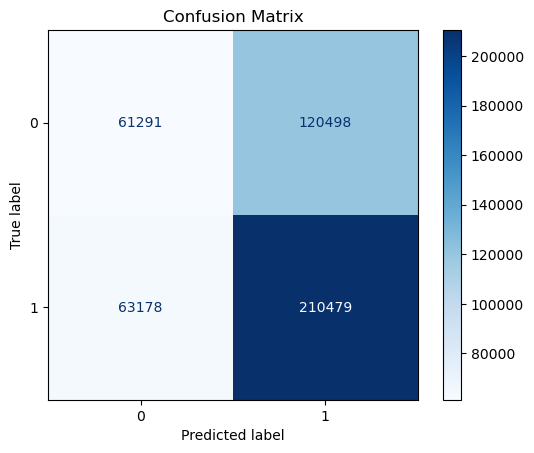

              precision    recall  f1-score   support

           0       0.49      0.34      0.40    181789
           1       0.64      0.77      0.70    273657

    accuracy                           0.60    455446
   macro avg       0.56      0.55      0.55    455446
weighted avg       0.58      0.60      0.58    455446



(tensor(0.5415), 271770, 455446)

In [22]:
test(model,data_load,loss_fn)

In [23]:
model_two = AdvancedModel(8)
optimizer_two = torch.optim.Adam(model_two.parameters(),learning_rate)

In [24]:
train(model_two,data_load,epochs,loss_fn,optimizer_two)

Epoch 01 | Training Loss: 0.5542 | Train Acc: 62.19% (2265763/3643560)
         | Val Loss:      0.5526 | Val Acc:   60.10% (273708/455445)
--------------------------------------------------------------------------------
Epoch 02 | Training Loss: 0.5142 | Train Acc: 76.50% (2787338/3643560)
         | Val Loss:      0.5502 | Val Acc:   77.13% (351281/455445)
--------------------------------------------------------------------------------
Epoch 03 | Training Loss: 0.4850 | Train Acc: 79.36% (2891390/3643560)
         | Val Loss:      0.5477 | Val Acc:   46.27% (210751/455445)
--------------------------------------------------------------------------------
Epoch 04 | Training Loss: 0.4561 | Train Acc: 79.47% (2895649/3643560)
         | Val Loss:      0.5449 | Val Acc:   56.65% (258028/455445)
--------------------------------------------------------------------------------
Epoch 05 | Training Loss: 0.4227 | Train Acc: 79.77% (2906631/3643560)
         | Val Loss:      0.5421 | Val Acc:  

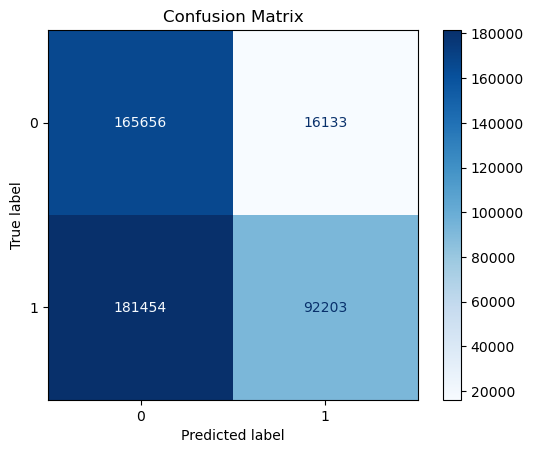

              precision    recall  f1-score   support

           0       0.48      0.91      0.63    181789
           1       0.85      0.34      0.48    273657

    accuracy                           0.57    455446
   macro avg       0.66      0.62      0.55    455446
weighted avg       0.70      0.57      0.54    455446



(tensor(0.5422), 257859, 455446)

In [25]:
test(model_two,data_load,loss_fn)

In [26]:
model_three = GATModel(8)
optimizer_three = torch.optim.Adam(model_three.parameters(),learning_rate)

In [27]:
train(model_three,data_load,epochs,loss_fn,optimizer_three)

Epoch 01 | Training Loss: 0.5594 | Train Acc: 39.90% (1453604/3643560)
         | Val Loss:      0.5573 | Val Acc:   39.90% (181737/455445)
--------------------------------------------------------------------------------
Epoch 02 | Training Loss: 0.5573 | Train Acc: 39.90% (1453604/3643560)
         | Val Loss:      0.5557 | Val Acc:   39.90% (181737/455445)
--------------------------------------------------------------------------------
Epoch 03 | Training Loss: 0.5557 | Train Acc: 39.90% (1453604/3643560)
         | Val Loss:      0.5547 | Val Acc:   39.90% (181737/455445)
--------------------------------------------------------------------------------
Epoch 04 | Training Loss: 0.5547 | Train Acc: 39.90% (1453604/3643560)
         | Val Loss:      0.5539 | Val Acc:   39.90% (181737/455445)
--------------------------------------------------------------------------------
Epoch 05 | Training Loss: 0.5539 | Train Acc: 39.90% (1453604/3643560)
         | Val Loss:      0.5533 | Val Acc:  

/opt/anaconda3/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/opt/anaconda3/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/opt/anaconda3/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


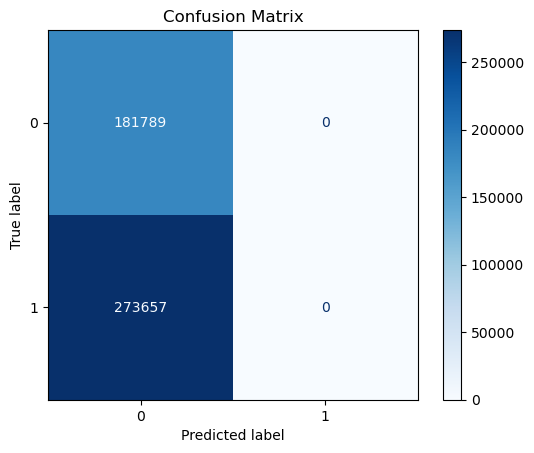

              precision    recall  f1-score   support

           0       0.40      1.00      0.57    181789
           1       0.00      0.00      0.00    273657

    accuracy                           0.40    455446
   macro avg       0.20      0.50      0.29    455446
weighted avg       0.16      0.40      0.23    455446



(tensor(0.5534), 181789, 455446)

In [28]:
test(model_three,data_load,loss_fn)

In [29]:
model_four = GENModel(8)
optimizer_fr = torch.optim.Adam(model_four.parameters(),learning_rate)

In [30]:
train(model_four,data_load,epochs,loss_fn,optimizer_fr)

Epoch 01 | Training Loss: 0.5594 | Train Acc: 39.90% (1453604/3643560)
         | Val Loss:      0.5550 | Val Acc:   39.90% (181737/455445)
--------------------------------------------------------------------------------
Epoch 02 | Training Loss: 0.5440 | Train Acc: 39.90% (1453604/3643560)
         | Val Loss:      0.5543 | Val Acc:   39.90% (181737/455445)
--------------------------------------------------------------------------------
Epoch 03 | Training Loss: 0.5311 | Train Acc: 51.76% (1885985/3643560)
         | Val Loss:      0.5536 | Val Acc:   39.90% (181737/455445)
--------------------------------------------------------------------------------
Epoch 04 | Training Loss: 0.5193 | Train Acc: 53.25% (1940275/3643560)
         | Val Loss:      0.5529 | Val Acc:   39.90% (181737/455445)
--------------------------------------------------------------------------------
Epoch 05 | Training Loss: 0.5087 | Train Acc: 75.73% (2759426/3643560)
         | Val Loss:      0.5521 | Val Acc:  

/opt/anaconda3/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/opt/anaconda3/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/opt/anaconda3/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


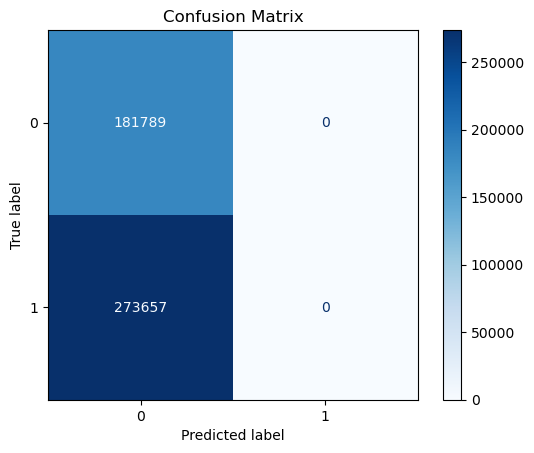

              precision    recall  f1-score   support

           0       0.40      1.00      0.57    181789
           1       0.00      0.00      0.00    273657

    accuracy                           0.40    455446
   macro avg       0.20      0.50      0.29    455446
weighted avg       0.16      0.40      0.23    455446



(tensor(0.5521), 181789, 455446)

In [31]:
test(model_four,data_load,loss_fn)